## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()



Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

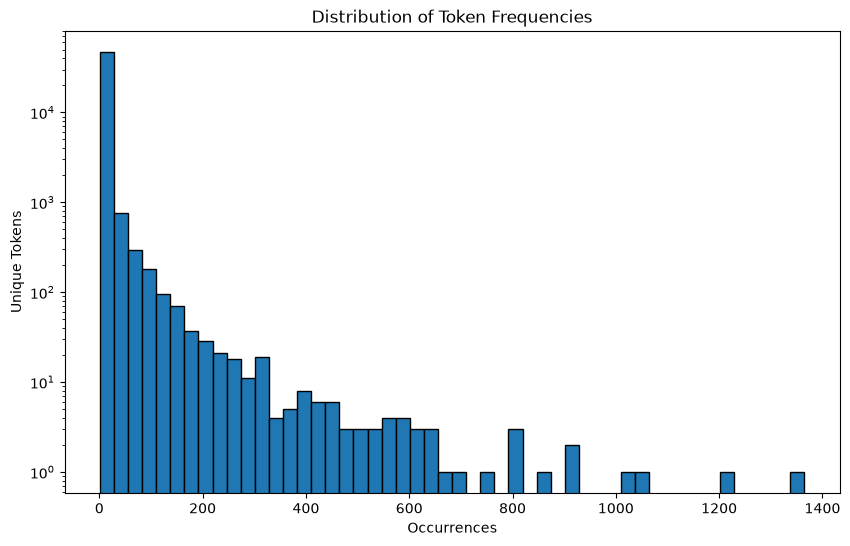

The distribution is heavily right-skewed, with the vast majority of tokens occurring 
"relatively infrequently. This suggests that a relatively small number of words are used very frequently 
"throughout the emails, with most words appearing only occasionally.


In [15]:
# Your Phase 1 solution to the problem goes here.
#Question 1
import matplotlib.pyplot as plt

frequencies = list(token_count.values())

# make histogram
plt.figure(figsize=(10, 6))
plt.hist(frequencies, bins=50, edgecolor='black')

plt.xlabel('Occurrences')
plt.ylabel('Unique Tokens')
plt.title('Distribution of Token Frequencies')
plt.yscale('log')
plt.show()

print("""The distribution is heavily right-skewed, with the vast majority of tokens occurring 
"relatively infrequently. This suggests that a relatively small number of words are used very frequently 
"throughout the emails, with most words appearing only occasionally.""")


In [16]:
#question 2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_parquet('data/Phishing_clean.parquet')

# separate variable and predictors 
X = df.drop(columns=['Email Type'])
y = df['Email Type']

#80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)


#linear regression
model = LinearRegression()
model.fit(X_train, y_train)

# predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# R-squared
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training R²:", train_r2)
print("Test R²:", test_r2)


# table of words with coefficients
coefficients = pd.DataFrame({
    'Word': X.columns,
    'Coefficient': model.coef_
})

# absolute coefficient values
coefficients['Absolute Coefficient'] = coefficients['Coefficient'].abs()

# largest absolute coefficients
coefficients = coefficients.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

# top 10 words
print(coefficients.head(10).to_string(index=False))

print("""The tokens with the largest coefficients in absolute value were "intervention" 
(-1.259), "localized" (0.824), "thermal" (0.747), and "crawler" (0.696). "Intervention" 
had the strongest negative association with phishing emails, while "localized" had the 
strongest positive association.""")

Training set: (14907, 2711)
Test set: (3727, 2711)
Training R²: 0.7670143724934355
Test R²: 0.6658718438847919
             Word  Coefficient  Absolute Coefficient
     intervention    -1.259257              1.259257
        localized     0.824350              0.824350
          thermal     0.747006              0.747006
          crawler     0.696167              0.696167
background-image:    -0.622909              0.622909
       helvetica,     0.598560              0.598560
            aging     0.594956              0.594956
            form.     0.576886              0.576886
            gray;    -0.574480              0.574480
         a:active     0.574480              0.574480
The tokens with the largest coefficients in absolute value were "intervention" 
(-1.259), "localized" (0.824), "thermal" (0.747), and "crawler" (0.696). "Intervention" 
had the strongest negative association with phishing emails, while "localized" had the 
strongest positive association.


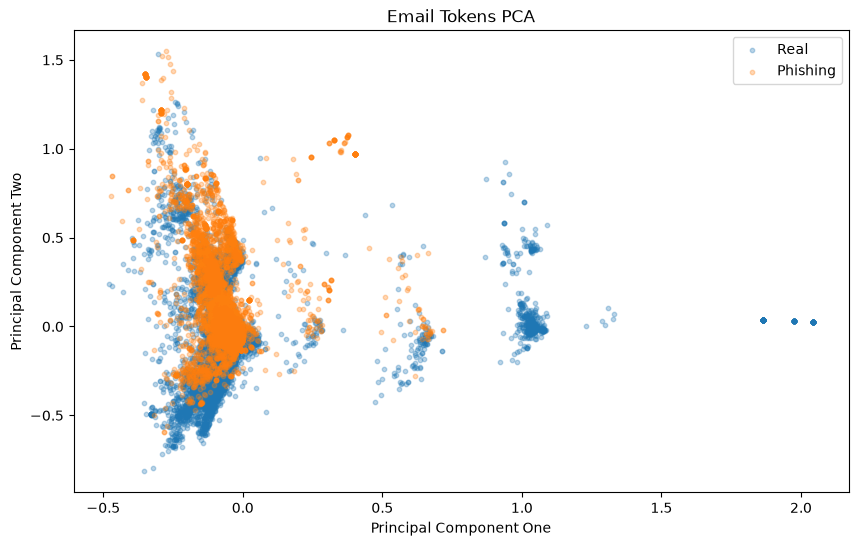

The PCA scatter plot shows overlap between phishing and legitimate emails, although 
there are some patterns. Phishing emails are more-often concentrated near the center and 
upper portions of the main cluster, while legitimate emails appear more frequently toward the 
bottom. There are also a few distinct clusters of legitimate emails further to the right along 
the first principal component. Overall, the first two principal components capture some 
differences between the two types of emails, but the overlap tells us that it may be difficult 
to clearly distinguish between them.


In [17]:
# question 3
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

#PCA with 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

#scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    X_pca[y == 0, 0],
    X_pca[y == 0, 1],
    alpha=0.3,
    s=10,
    label='Real'
)
plt.scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    alpha=0.3,
    s=10,
    label='Phishing'
)

plt.xlabel('Principal Component One')
plt.ylabel('Principal Component Two')
plt.title('Email Tokens PCA')
plt.legend()
plt.show()

print("""The PCA scatter plot shows overlap between phishing and legitimate emails, although 
there are some patterns. Phishing emails are more-often concentrated near the center and 
upper portions of the main cluster, while legitimate emails appear more frequently toward the 
bottom. There are also a few distinct clusters of legitimate emails further to the right along 
the first principal component. Overall, the first two principal components capture some 
differences between the two types of emails, but the overlap tells us that it may be difficult 
to clearly distinguish between them.""")


In [ ]:
#Question 4
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

#PCA with 2610 components
pca_full = PCA(n_components=2610, svd_solver='randomized', random_state=42)

# fit the PCA on training data
X_train_pca = pca_full.fit_transform(X_train)

# transform test data
X_test_pca = pca_full.transform(X_test)

# linear regression
pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

#predictions
y_train_pred_pca = pca_model.predict(X_train_pca)
y_test_pred_pca = pca_model.predict(X_test_pca)

# r-squared
train_r2_pca = r2_score(y_train, y_train_pred_pca)
test_r2_pca = r2_score(y_test, y_test_pred_pca)

print("PCA Training R²:", train_r2_pca)
print("PCA Test R²:", test_r2_pca)

#compare with original regression
print("Original Training R²:", train_r2)
print("Original Test R²:", test_r2)

print("""The regression using the first 2,610 principal components produced an R² of 0.7662 
on the training set and 0.6684 on the test set. In comparison, the original linear regression 
had a training R² of 0.7670 and a test R² of 0.6659. So the PCA model performed slightly 
worse on the training data but slightly better on the test data. This suggests that PCA was 
able to reduce the number of features while preserving nearly all of the model's predictive 
performance. Also please note that when I reran everything my kernel crashed so I think I ran 
out of memory, so that is why the numbers are not displayed, but I did cite them in my answer
below.
""")


: 

In [14]:
#question 5
print("""The main advantage of PCA is that it reduces the dimensionality of the data while 
preserving as much variation as possible. Instead of using thousands of individual word 
features, PCA creates components to summarize data. This can reduce redundancy between predictors 
and potentially limit overfitting. Here, PCA reduced the number of features from 2,711 to 
2,610 while slightly improving the test R², demonstrating that we can simplify the model 
without sacrificing predictive performance. """)

The main advantage of PCA is that it reduces the dimensionality of the data while 
preserving as much variation as possible. Instead of using thousands of individual word 
features, PCA creates components to summarize data. This can reduce redundancy between predictors 
and potentially limit overfitting. Here, PCA reduced the number of features from 2,711 to 
2,610 while slightly improving the test R², demonstrating that we can simplify the model 
without sacrificing predictive performance. 


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [7]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]